In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
file_path = r'/home/clayg/txt2onto/data/bacteria_BioSample.csv'

df = pd.read_csv(file_path)

/tmp/ipykernel_2341/1615042877.py:3: DtypeWarning: Columns (0: host_taxid, 1: host_health, 2: host_name, 3: host_comments, 4: isolation_comments, 5: comments) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


In [3]:
df.columns.to_list()

['Unnamed: 0.1',
 'Unnamed: 0',
 'biosample_accession',
 'sample_taxon_id',
 'sample_taxonomy_name',
 'host_taxid',
 'host_health',
 'host_name',
 'host_comments',
 'isolation_comments',
 'comments']

In [4]:
print(f"There are {len(df)} BioSamples in the dataset.")
print(f"There are {len(df['host_name'].unique())} unique host values.")
nans = len(df) - len(df['host_name'].dropna())
print(f"There are {nans} unlabeled BioSamples")

There are 6956432 BioSamples in the dataset.
There are 16879 unique host values.
There are 4724435 unlabeled BioSamples


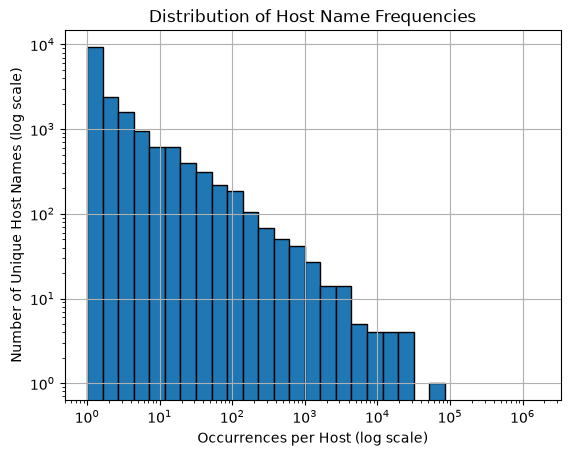

In [5]:
host_counts = df['host_name'].value_counts()
bins = np.logspace(np.log10(host_counts.min()), np.log10(host_counts.max()), num=30)

# Plot histogram with log scales
host_counts.hist(bins=bins, edgecolor='black')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Occurrences per Host (log scale)')
plt.ylabel('Number of Unique Host Names (log scale)')
plt.title('Distribution of Host Name Frequencies')
plt.show()

In [6]:
import re

human_names = ['homo', 'homo sapiens', 'human', 'patient', 'homo sapien', 'man', 'woman', '9606']

# Sort by length descending to match longer multi-word phrases first, then wrap in word boundaries
pattern = r'\b(?:' + '|'.join(re.escape(name) for name in sorted(human_names, key=len, reverse=True)) + r')\b'

# Create the boolean mask
mask = df['host_name'].str.contains(pattern, case=False, na=False, regex=True)


In [7]:
human_host = df[mask]
print(f"Total rows containing human terms in host column before filtering: {len(human_host)}")
unique_human_labels = human_host['host_name'].unique()
print(len(unique_human_labels))
unique_human_labels

Total rows containing human terms in host column before filtering: 1641531
562


<StringArray>
[                 'Homo sapiens',                  'human sputum',
                         'Human',      'Homo sapiens, freshwater',
            'homo sapiens, soil',          'Hospitalized patient',
 'Human blood, renal transplant',                  'homo sapiens',
         'Human (male, 4.5 yrs)',             'Human (Female 16)',
 ...
                      'Human-37',                      'Human-38',
                      'Human-39',                      'Human-40',
                      'Human-41',                      'Human-42',
                      'Human-43',                      'Human-44',
                      'Human-45',                      'Human-46']
Length: 562, dtype: str

In [8]:
def find_sample(text:str, data):
    mask = df['host_name'] == text
    return df[mask]

search = 'Homo sapiens, freshwater'
search_result = find_sample(search, df)
search_result

,Unnamed: 0.1,Unnamed: 0,biosample_accession,sample_taxon_id,sample_taxonomy_name,host_taxid,host_health,host_name,host_comments,isolation_comments,comments
16334,651310,651310,SAMN00713582,2703885,Rahnella aceris,NaN,NaN,"Homo sapiens, freshwater",NaN,"DOE Field Research Center (FRC), Oak Ridge, TN...",NaN


In [30]:
import os

output_dir = "/home/clayg/txt2onto/data"
os.makedirs(output_dir, exist_ok=True)
output_file = os.path.join(output_dir, "output.txt")

with open(output_file, "w", encoding="utf-8") as f:
    for item in unique_human_labels:
        if pd.isna(item):
            f.write("\n")  # or skip with 'continue' if you don't want empty lines for NAs
        else:
            f.write(f"{item}\n")

Located terms which could not be confidently considered to be human hosts to remove from the list

In [9]:
nonhuman_names = [
    "Homo sapiens, freshwater",
    "homo sapiens, soil",
    "HUMAN/FOOD",
    "non human primate",
    "Human/Culture",
    "Homo sapiens and Environment",
    "non-human primate",
    "Non-human primate",
    "In human and animal",
    "dog and human",
    "Non-human",
    "non-human",
    "marmot and human",
    "mouse/human",
    "human and other animals",
    "Human, livestock",
    "Non Human Primate",
    "Sheep and human",
    "Homo sapiens and other mammals",
]



In [10]:
before = len(human_host)
human_host = human_host[~human_host['host_name'].isin(nonhuman_names)]
after = len(human_host)

print(f"Removed {before-after} rows")

Removed 816 rows


In [11]:
after

1640715

In [12]:
#Create a list of host labeled samples which are not in the human host dataset
non_human_host = df.dropna(subset='host_name')

non_human_host = non_human_host[
    ~non_human_host['biosample_accession'].isin(human_host['biosample_accession'])
]

Because we have such a massive list of human labeled hosts, we can filter to high quality samples for training. Let's narrow in from here. 

In [13]:
duplicates = len(human_host['isolation_comments']) - len(human_host['isolation_comments'].drop_duplicates())
print (duplicates)
print(len(human_host['isolation_comments'].drop_duplicates()))

1594532
46183


In [14]:
human_host = human_host.drop_duplicates(subset='isolation_comments')

We'll do the same for non-human hosts

In [15]:
duplicates = len(non_human_host['isolation_comments']) - len(non_human_host['isolation_comments'].drop_duplicates())

print(duplicates)
print(len(non_human_host['isolation_comments'].drop_duplicates()))

555784
35498


In [16]:
non_human_host = non_human_host.drop_duplicates(subset='isolation_comments')

In [17]:
nans = df[df['host_name'].isna()]  # unlabeled: no host_name

duplicates = len(nans['isolation_comments']) - len(nans['isolation_comments'].drop_duplicates())

print(duplicates)
print(len(nans['isolation_comments'].drop_duplicates()))

2151339
80658


In [18]:
nans = nans.drop_duplicates(subset='isolation_comments')

Create a new is_human column for each dataset 

In [19]:
human_host['is_human'] = 1
non_human_host['is_human'] = -1
nans['is_human'] = 0

In [20]:
human_host.head()

,Unnamed: 0.1,Unnamed: 0,biosample_accession,sample_taxon_id,sample_taxonomy_name,host_taxid,host_health,host_name,host_comments,isolation_comments,comments,is_human
0,0,0,SAMN00000002,445970,Alistipes putredinis DSM 17216,9606.0,NaN,Homo sapiens,NaN,missing,NaN,1
10,14,14,SAMN00000016,470146,Coprococcus comes ATCC 27758,9606.0,NaN,Homo sapiens,NaN,ATCC:27758; missing,NaN,1
13,17,17,SAMN00000019,471881,Proteus penneri ATCC 35198,9606.0,NaN,Homo sapiens,NaN,ATCC:35198; missing,NaN,1
16,20,20,SAMN00000022,471875,[Ruminococcus] lactaris ATCC 29176,9606.0,NaN,Homo sapiens,NaN,ATCC:29176; missing,NaN,1
78,295,295,SAMN00000299,509633,Pseudomonas aeruginosa PAb1,NaN,NaN,Homo sapiens,NaN,clininal isolate from frostbite patient,NaN,1


In [21]:
final_df = pd.concat([human_host, non_human_host, nans])

In [22]:
final_df['is_human'].value_counts()

is_human
 0    80658
 1    46183
-1    35498
Name: count, dtype: int64

In [23]:
len(final_df)

162339

In [23]:
final_df.to_csv(r"/home/clayg/txt2onto/data/human_labeled_biosamples.csv")

Querying OmicIDX DuckDB for related bioprojects to assist with grouping and train/test split

In [205]:
import duckdb
import pandas as pd

con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs;")
con.register("my_samples", final_df[['biosample_accession']])

query = """
    SELECT 
        b.accession,
        
        -- Check the flat IDs array
        list_filter(b.ids, x -> x LIKE 'PRJ%') AS found_in_ids,
        
        -- Check custom attributes for the word 'project' or a PRJ value
        list_transform(
            list_filter(b.attribute_recs, x -> lower(x.attribute_name) LIKE '%project%' OR x.value LIKE 'PRJ%'), 
            y -> y.attribute_name || ': ' || y.value
        ) AS found_in_attributes

    FROM read_parquet('https://data-omicidx.cancerdatasci.org/biosample/parquet/biosamples.parquet') b
    SEMI JOIN my_samples s 
        ON b.accession = s.biosample_accession
    WHERE 
        CAST(b.ids AS VARCHAR) LIKE '%PRJ%' 
        OR CAST(b.attribute_recs AS VARCHAR) LIKE '%PRJ%'
    LIMIT 20
"""

diagnostic_df = con.execute(query).df()
print(diagnostic_df.to_string())

       accession                                    found_in_ids                                         found_in_attributes
0   SAMN00139625                       [PRJNA38063.E. coli E101]                                                          []
1   SAMN00627898        [PRJNA28331.Paenibacillus sp. 4_7_47FAA]                                                          []
2   SAMN00627901  [PRJNA28331.Parabacteroides merdae CL03T12C32]                                                          []
3   SAMN01090322                                   [PRJNA163767]                                                          []
4   SAMN02363423                                              []                                    [BioProject: PRJNA13923]
5   SAMN02363424                                              []                                    [BioProject: PRJNA13924]
6   SAMN04100022                                              []        [BioProject: PRJNA293615, project name: PRJNA293615]


In [212]:
import duckdb
import pandas as pd

# 1. Drop existing column to ensure a clean merge
if 'bioproject_accession' in final_df.columns:
    final_df = final_df.drop(columns=['bioproject_accession'])

con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs;")
con.register("my_samples", final_df[['biosample_accession']])

query = """
    SELECT 
        b.accession AS biosample_accession,
        
        COALESCE(
            -- Stringify the entire ids array and extract all matches
            NULLIF(array_to_string(list_distinct(
                regexp_extract_all(CAST(b.ids AS VARCHAR), 'PRJ[a-zA-Z]{2}[0-9]+')
            ), '; '), ''),
            
            -- Stringify the entire attribute_recs struct array and extract all matches
            NULLIF(array_to_string(list_distinct(
                regexp_extract_all(CAST(b.attribute_recs AS VARCHAR), 'PRJ[a-zA-Z]{2}[0-9]+')
            ), '; '), '')
        ) AS bioproject_accession

    FROM read_parquet('https://data-omicidx.cancerdatasci.org/biosample/parquet/biosamples.parquet') b
    SEMI JOIN my_samples s
        ON b.accession = s.biosample_accession
"""

print("Querying OmicIDX for BioProject IDs in arrays and attributes...")
project_mapping = con.execute(query).df()

# Convert any empty strings from failed regex matches to true nulls before merging
project_mapping['bioproject_accession'] = project_mapping['bioproject_accession'].replace('', pd.NA)

# 2. Merge the clean mapping back into final_df
final_df = final_df.merge(project_mapping, on='biosample_accession', how='left')

# 3. Report Success
success_rate = final_df['bioproject_accession'].notna().mean() * 100
print(f"Combined BioProject extraction success rate: {success_rate:.2f}%")
print("\nSample Output:")
print(final_df[['biosample_accession', 'bioproject_accession']].dropna().head())

Querying OmicIDX for BioProject IDs in arrays and attributes...
Combined BioProject extraction success rate: 1.43%

Sample Output:
     biosample_accession bioproject_accession
227         SAMN00627898           PRJNA28331
228         SAMN00627901           PRJNA28331
510         SAMN02363423           PRJNA13923
511         SAMN02363424           PRJNA13924
3371        SAMN04100029          PRJNA293615


In [28]:
import time
import json
from pathlib import Path
from http.client import IncompleteRead, HTTPException
from urllib.error import HTTPError, URLError

import pandas as pd
from Bio import Entrez

import os

# Credentials come from the environment (see README); never hard-code the key
Entrez.email = os.environ["NCBI_EMAIL"]
Entrez.api_key = os.environ.get("NCBI_API_KEY")

CHECKPOINT_FILE = Path("entrez_mapping_checkpoint.json")
TRANSIENT_ERRORS = (HTTPError, URLError, IncompleteRead, HTTPException, RuntimeError)

if "bioproject_accession" not in final_df.columns:
    final_df["bioproject_accession"] = None

# Resume from a previous run if a checkpoint exists
new_mappings = json.loads(CHECKPOINT_FILE.read_text()) if CHECKPOINT_FILE.exists() else {}
if new_mappings:
    print(f"Resuming: {len(new_mappings)} mappings already on disk.")

unmapped_df = final_df[final_df['bioproject_accession'].isna()]
accessions_to_map = [a for a in unmapped_df['biosample_accession'].tolist() if a not in new_mappings]
print(f"Starting Entrez mapping for {len(accessions_to_map)} BioSamples...")

chunk_size = 200

def biosample_acc_to_uid(accessions):
    """Resolve a batch of BioSample accessions to their internal Entrez UIDs."""
    term = " OR ".join(f"{acc}[Accession]" for acc in accessions)
    handle = Entrez.esearch(db="biosample", term=term, retmax=len(accessions))
    record = Entrez.read(handle)
    handle.close()
    return record["IdList"]



def fetch_chunk(chunk, max_attempts=4):
    for attempt in range(1, max_attempts + 1):
        try:
            bs_uids_in = biosample_acc_to_uid(chunk)
            if not bs_uids_in:
                return {acc: None for acc in chunk}

            link_handle = Entrez.elink(dbfrom="biosample", db="bioproject", id=bs_uids_in)
            link_records = Entrez.read(link_handle)
            link_handle.close()

            bs_to_bp_uid, bp_uids = {}, []
            for record in link_records:
                if record.get('LinkSetDb'):
                    bs_uid = record['IdList'][0]
                    bp_uid = record['LinkSetDb'][0]['Link'][0]['Id']
                    bs_to_bp_uid[bs_uid] = bp_uid
                    bp_uids.append(bp_uid)
            if not bp_uids:
                return {acc: None for acc in chunk}

            bp_sum_handle = Entrez.esummary(db="bioproject", id=",".join(bp_uids))
            bp_sum_records = Entrez.read(bp_sum_handle)
            bp_sum_handle.close()
            bp_uid_to_acc = {
                doc.attributes['uid']: doc['Project_Acc']
                for doc in bp_sum_records['DocumentSummarySet']['DocumentSummary']
                if 'Project_Acc' in doc
            }

            bs_uids = list(bs_to_bp_uid.keys())
            bs_sum_handle = Entrez.esummary(db="biosample", id=",".join(bs_uids))
            bs_sum_records = Entrez.read(bs_sum_handle)
            bs_sum_handle.close()
            bs_uid_to_acc = {
                doc.attributes['uid']: doc['Accession']
                for doc in bs_sum_records['DocumentSummarySet']['DocumentSummary']
                if 'Accession' in doc
            }

            successful_mappings = {
                bs_uid_to_acc[bs]: bp_uid_to_acc[bp]
                for bs, bp in bs_to_bp_uid.items()
                if bs in bs_uid_to_acc and bp in bp_uid_to_acc
            }
            
            # Return the whole chunk. If it wasn't successful, mark it None.
            return {acc: successful_mappings.get(acc, None) for acc in chunk}
            
        except TRANSIENT_ERRORS as e:
            wait = 5 * attempt
            print(f"\n  Transient error (attempt {attempt}/{max_attempts}): {e!r}. Retrying in {wait}s...")
            time.sleep(wait)
    print("\n  Giving up on this chunk after max attempts — will retry on next run.")
    return {}

for i in range(0, len(accessions_to_map), chunk_size):
    chunk = accessions_to_map[i:i + chunk_size]
    new_mappings.update(fetch_chunk(chunk))
    print(f"Processed {i}-{i+len(chunk)}... ({len(new_mappings)} total mapped)", end="\r")
    time.sleep(0.35)

    if (i // chunk_size) % 10 == 0:  # checkpoint every 10 chunks
        CHECKPOINT_FILE.write_text(json.dumps(new_mappings))

CHECKPOINT_FILE.write_text(json.dumps(new_mappings))
print("\nFinished Entrez mapping.")

Resuming: 47650 mappings already on disk.
Starting Entrez mapping for 67565 BioSamples...

  Transient error (attempt 1/4): IncompleteRead(167 bytes read). Retrying in 5s...

  Transient error (attempt 2/4): IncompleteRead(167 bytes read). Retrying in 10s...


KeyboardInterrupt: 

In [215]:
test_acc = 'SAMN00627898'
h = Entrez.esearch(db="biosample", term=f"{test_acc}[Accession]")
print(Entrez.read(h))

{'Count': '1', 'RetMax': '1', 'RetStart': '0', 'IdList': ['627898'], 'TranslationSet': [], 'TranslationStack': [{'Term': 'SAMN00627898[Accession]', 'Field': 'Accession', 'Count': '1', 'Explode': 'N'}, 'GROUP'], 'QueryTranslation': 'SAMN00627898[Accession]'}
